# Plot Radiometric Response Curves

In [ ]:
library(tidyverse)
library(patchwork)
library(RColorBrewer)
library(dplyr)

Warning message:
“package ‘tidyverse’ was built under R version 4.4.3”
Warning message:
“package ‘ggplot2’ was built under R version 4.4.3”
Warning message:
“package ‘tibble’ was built under R version 4.4.3”
Warning message:
“package ‘tidyr’ was built under R version 4.4.3”
Warning message:
“package ‘readr’ was built under R version 4.4.3”
Warning message:
“package ‘purrr’ was built under R version 4.4.3”
Warning message:
“package ‘dplyr’ was built under R version 4.4.3”
Warning message:
“package ‘stringr’ was built under R version 4.4.3”
Warning message:
“package ‘forcats’ was built under R version 4.4.3”
Warning message:
“package ‘lubridate’ was built under R version 4.4.3”
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ──────────────────────────────────────

In [ ]:
#MAINDIR = '/explore/nobackup/projects/CSDA_eval/results/maxar/legion/geometric'

band_colors <- c(
  'Pan' = 'gray',
  'Coastal'  = '#4f3a89', 'Blue'     = '#1f78b4',
  'Green'    = '#33a02c', 'Yellow'   = '#ffd92f',
  'Red'      = '#e31a1c', 
  'RedEdge' = '#b15928',
  'RedEdge1' = '#b15928',
  'RedEdge2' = '#8b3a00', 'NIR' = 'indianred','NIR1'     = 'indianred' #'#525252'
)

band_order <- c('Pan','Coastal', 'Blue', 'Green', 'Yellow', 'Red',
                'RedEdge','RedEdge1', 'RedEdge2', 'NIR','NIR1'
)

sat_colors <- c(
  'LG01' = '#1b9e77', 'LG02' = '#d95f02', 'LG03' = '#7570b3',
  'LG04' = '#e7298a', 'LG05' = '#66a61e', 'LG06' = '#e6ab02',
  'LG07' = '#a6761d', 'LG08' = '#666666', 'LG09' = '#1f78b4'
)

In [ ]:
# Define the root search path
search_path <- "/explore/nobackup/projects/CSDA_eval/results"

### RSR Curves

In [ ]:
rsr_files = list.files(
    path = search_path,
    pattern = "RSR.*\\.csv$",
    recursive = TRUE,
    full.names = TRUE
)
df_rsr <- rsr_files %>%
  set_names() %>%
  map_df(read_csv, .id = "source_file") %>%
  mutate(
    affiliation = if_else(str_detect(sensor, "^LG0"), "Vantor", 
                          if_else(str_detect(sensor, "^newsat"), "Satellogic", 
                                  if_else(str_detect(sensor, "^PHR1"), "Airbus", 
                                          if_else(str_detect(sensor, "^PNEO"), "Airbus", 
                                                  if_else(str_detect(sensor, "^SPOT"), "Airbus", 
                                                          if_else(str_detect(sensor, "^BS"), "BlackSky", NA_character_)))))),
    constellation = if_else(str_detect(sensor, "^LG0"), "Legion", 
                            if_else(str_detect(sensor, "^newsat"), "Aleph-1", 
                                    if_else(str_detect(sensor, "^PHR1"), "Pleiades", 
                                            if_else(str_detect(sensor, "^PNEO"), "PleiadesNeo", 
                                                    if_else(str_detect(sensor, "^SPOT"), "SPOT", 
                                                            if_else(str_detect(sensor, "^BS"), "Global", NA_character_)))))),
    band = as.character(band),
    band = case_when(
      str_detect(band, 'Coastal') ~ 'Coastal',
      str_detect(band, 'Red_Edge') ~ 'RedEdge',
      TRUE ~ band
    ),
    band = factor(band, levels = band_order),
    sensor = factor(sensor)
  ) %>% 
  select(-source_file, everything(), source_file) %>%
  droplevels()

Rows: 1045 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): sensor, band
dbl (2): wavelength_nm, rsr

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 1145 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): sensor, band
dbl (2): wavelength_nm, rsr

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 5257 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): sensor, band
dbl (2): wavelength_nm, rsr

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 5257 Columns: 4
── Column

### Load and integrate Planet RSR Data

The Planet RSR files have different header names and wavelength units. The code below reads them all, normalizes the columns, and combines with the existing df_rsr dataframe.

In [ ]:
# Helper function to read and normalize Planet RSR files
read_planet_rsr <- function(file_path) {
  # Read the file
  df <- read_csv(file_path, show_col_types = FALSE)
  
  # Get the filename for sensor extraction
  filename <- basename(file_path)
  
  # Standardize column names - rename first column to wavelength
  df <- df %>%
    rename_with(~"wavelength", 1) %>%
    rename_all(tolower)
  
  # Convert wavelength to nm if needed
  # If wavelengths are small (< 50), assume micrometers; if >= 200, assume nanometers
  if (min(df$wavelength, na.rm = TRUE) < 50) {
    df <- df %>% mutate(wavelength = wavelength * 1000)
  }
  df <- df %>% rename(wavelength_nm = wavelength)
  
  # Pivot to long format, keeping wavelength_nm and pivoting spectral bands
  df <- df %>%
    pivot_longer(
      cols = -wavelength_nm,
      names_to = "band",
      values_to = "rsr",
      values_drop_na = FALSE
    ) %>%
    # Clean up band names - remove extra text and spaces
    mutate(
      band = str_trim(band),
      band = str_replace_all(band, "_i i", ""),
      band = str_replace_all(band, "_i$", ""),
      band = str_replace_all(band, " response$", ""),
      band = str_replace_all(band, "-blue", ""),
      band = case_when(
        str_detect(band, "coastal|blue") ~ "Blue",
        str_detect(band, "green") ~ "Green",
        str_detect(band, "yellow") ~ "Yellow",
        str_detect(band, "red edge|red-edge") ~ "RedEdge",
        str_detect(band, "^red$") ~ "Red",
        str_detect(band, "nir|near") ~ "NIR",
        str_detect(band, "^pan$") ~ "Pan",
        TRUE ~ str_to_title(band)
      )
    )
  
  # Extract sensor and constellation from filename
  sensor_info <- case_when(
    str_detect(filename, "dove_r|Dove") ~ list(sensor = "Dove", constellation = "Dove"),
    str_detect(filename, "PlanetScope|planetscope") ~ {
      sat_id <- str_extract(filename, "(?<=SatID_)[0-9a-fA-F]+")
      if (is.na(sat_id)) sat_id <- "PlanetScope"
      list(sensor = paste0("PlanetScope_", sat_id), constellation = "PlanetScope")
    },
    str_detect(filename, "RapidEye") ~ list(sensor = "RapidEye", constellation = "RapidEye"),
    str_detect(filename, "Skysat|SkySat") ~ {
      sat_num <- str_extract(filename, "(?i)(?<=skysat).*?(?=\\.csv)")
      if (is.na(sat_num)) sat_num <- "SkySat"
      list(sensor = paste0("SkySat_", sat_num), constellation = "SkySat")
    },
    str_detect(filename, "Superdove") ~ list(sensor = "Superdove", constellation = "Superdove"),
    TRUE ~ list(sensor = str_remove(filename, "\\.csv$"), constellation = "Planet")
  )
  
  df <- df %>%
    mutate(
      sensor = sensor_info$sensor,
      affiliation = "Planet",
      constellation = sensor_info$constellation
    )
  
  return(df)
}

# Read all Planet RSR files
planet_dir <- "/home/pmontesa/CSDA_eval/results/planet"
planet_files <- list.files(planet_dir, pattern = "\\.csv$", full.names = TRUE)

# Use safely to handle any files that might fail to read
df_planet_rsr <- planet_files %>%
  map_df(safely(read_planet_rsr), .id = NULL) %>%
  filter(!is.na(result)) %>%
  unnest(result) %>%
  select(-error) %>%
  mutate(sensor = factor(sensor)) %>%
  droplevels()

# Combine with existing df_rsr
df_rsr_combined <- bind_rows(
  df_rsr %>%
    mutate(
      band = as.character(band),
      sensor = as.character(sensor)
    ),
  df_planet_rsr %>%
    select(wavelength_nm, rsr, sensor, band, affiliation, constellation)
) %>%
  mutate(
    # Standardize band names across all sources
    band = case_when(
      str_detect(band, 'Coastal|Coastal-Blue') ~ 'Coastal',
      str_detect(band, 'Red.?[Ee]dge|RedEdge') ~ 'RedEdge',
      TRUE ~ band
    ),
    band = factor(band, levels = band_order),
    sensor = factor(sensor)
  ) %>%
  droplevels()

# Replace df_rsr with the combined version
df_rsr <- df_rsr_combined

cat("Loaded", nrow(df_planet_rsr), "rows from", length(planet_files), "Planet RSR files\n")
cat("Total rows in combined df_rsr:", nrow(df_rsr), "\n")
cat("Affiliations:", paste(unique(df_rsr$affiliation), collapse = ", "), "\n")
cat("Constellations:", paste(unique(df_rsr$constellation), collapse = ", "), "\n")

In [ ]:
# Diagnostic: Check what's in df_rsr after combining
cat("Unique affiliations in df_rsr:\n")
print(table(df_rsr$affiliation))
cat("\n")
cat("Unique constellations in df_rsr:\n")
print(table(df_rsr$constellation))
cat("\n")

# Check for Planet data specifically
planet_count <- sum(df_rsr$affiliation == "Planet", na.rm = TRUE)
cat("Number of Planet rows:", planet_count, "\n")

# Show sample of Planet data if it exists
if (planet_count > 0) {
  cat("\nSample of Planet data:\n")
  df_rsr %>% filter(affiliation == "Planet") %>% slice_head(n = 10) %>% print()
}

In [ ]:
head(df_rsr)

sensor,band,wavelength_nm,rsr,affiliation,constellation,source_file
<fct>,<fct>,<dbl>,<dbl>,<chr>,<chr>,<chr>
PHR1A,Pan,430.0,0,Airbus,Pleiades,/explore/nobackup/projects/CSDA_eval/results/airbus/RSR_PHR1A.csv
PHR1A,Pan,432.5,0,Airbus,Pleiades,/explore/nobackup/projects/CSDA_eval/results/airbus/RSR_PHR1A.csv
PHR1A,Pan,435.0,0,Airbus,Pleiades,/explore/nobackup/projects/CSDA_eval/results/airbus/RSR_PHR1A.csv
PHR1A,Pan,437.5,0,Airbus,Pleiades,/explore/nobackup/projects/CSDA_eval/results/airbus/RSR_PHR1A.csv
PHR1A,Pan,440.0,0,Airbus,Pleiades,/explore/nobackup/projects/CSDA_eval/results/airbus/RSR_PHR1A.csv
PHR1A,Pan,442.5,0,Airbus,Pleiades,/explore/nobackup/projects/CSDA_eval/results/airbus/RSR_PHR1A.csv


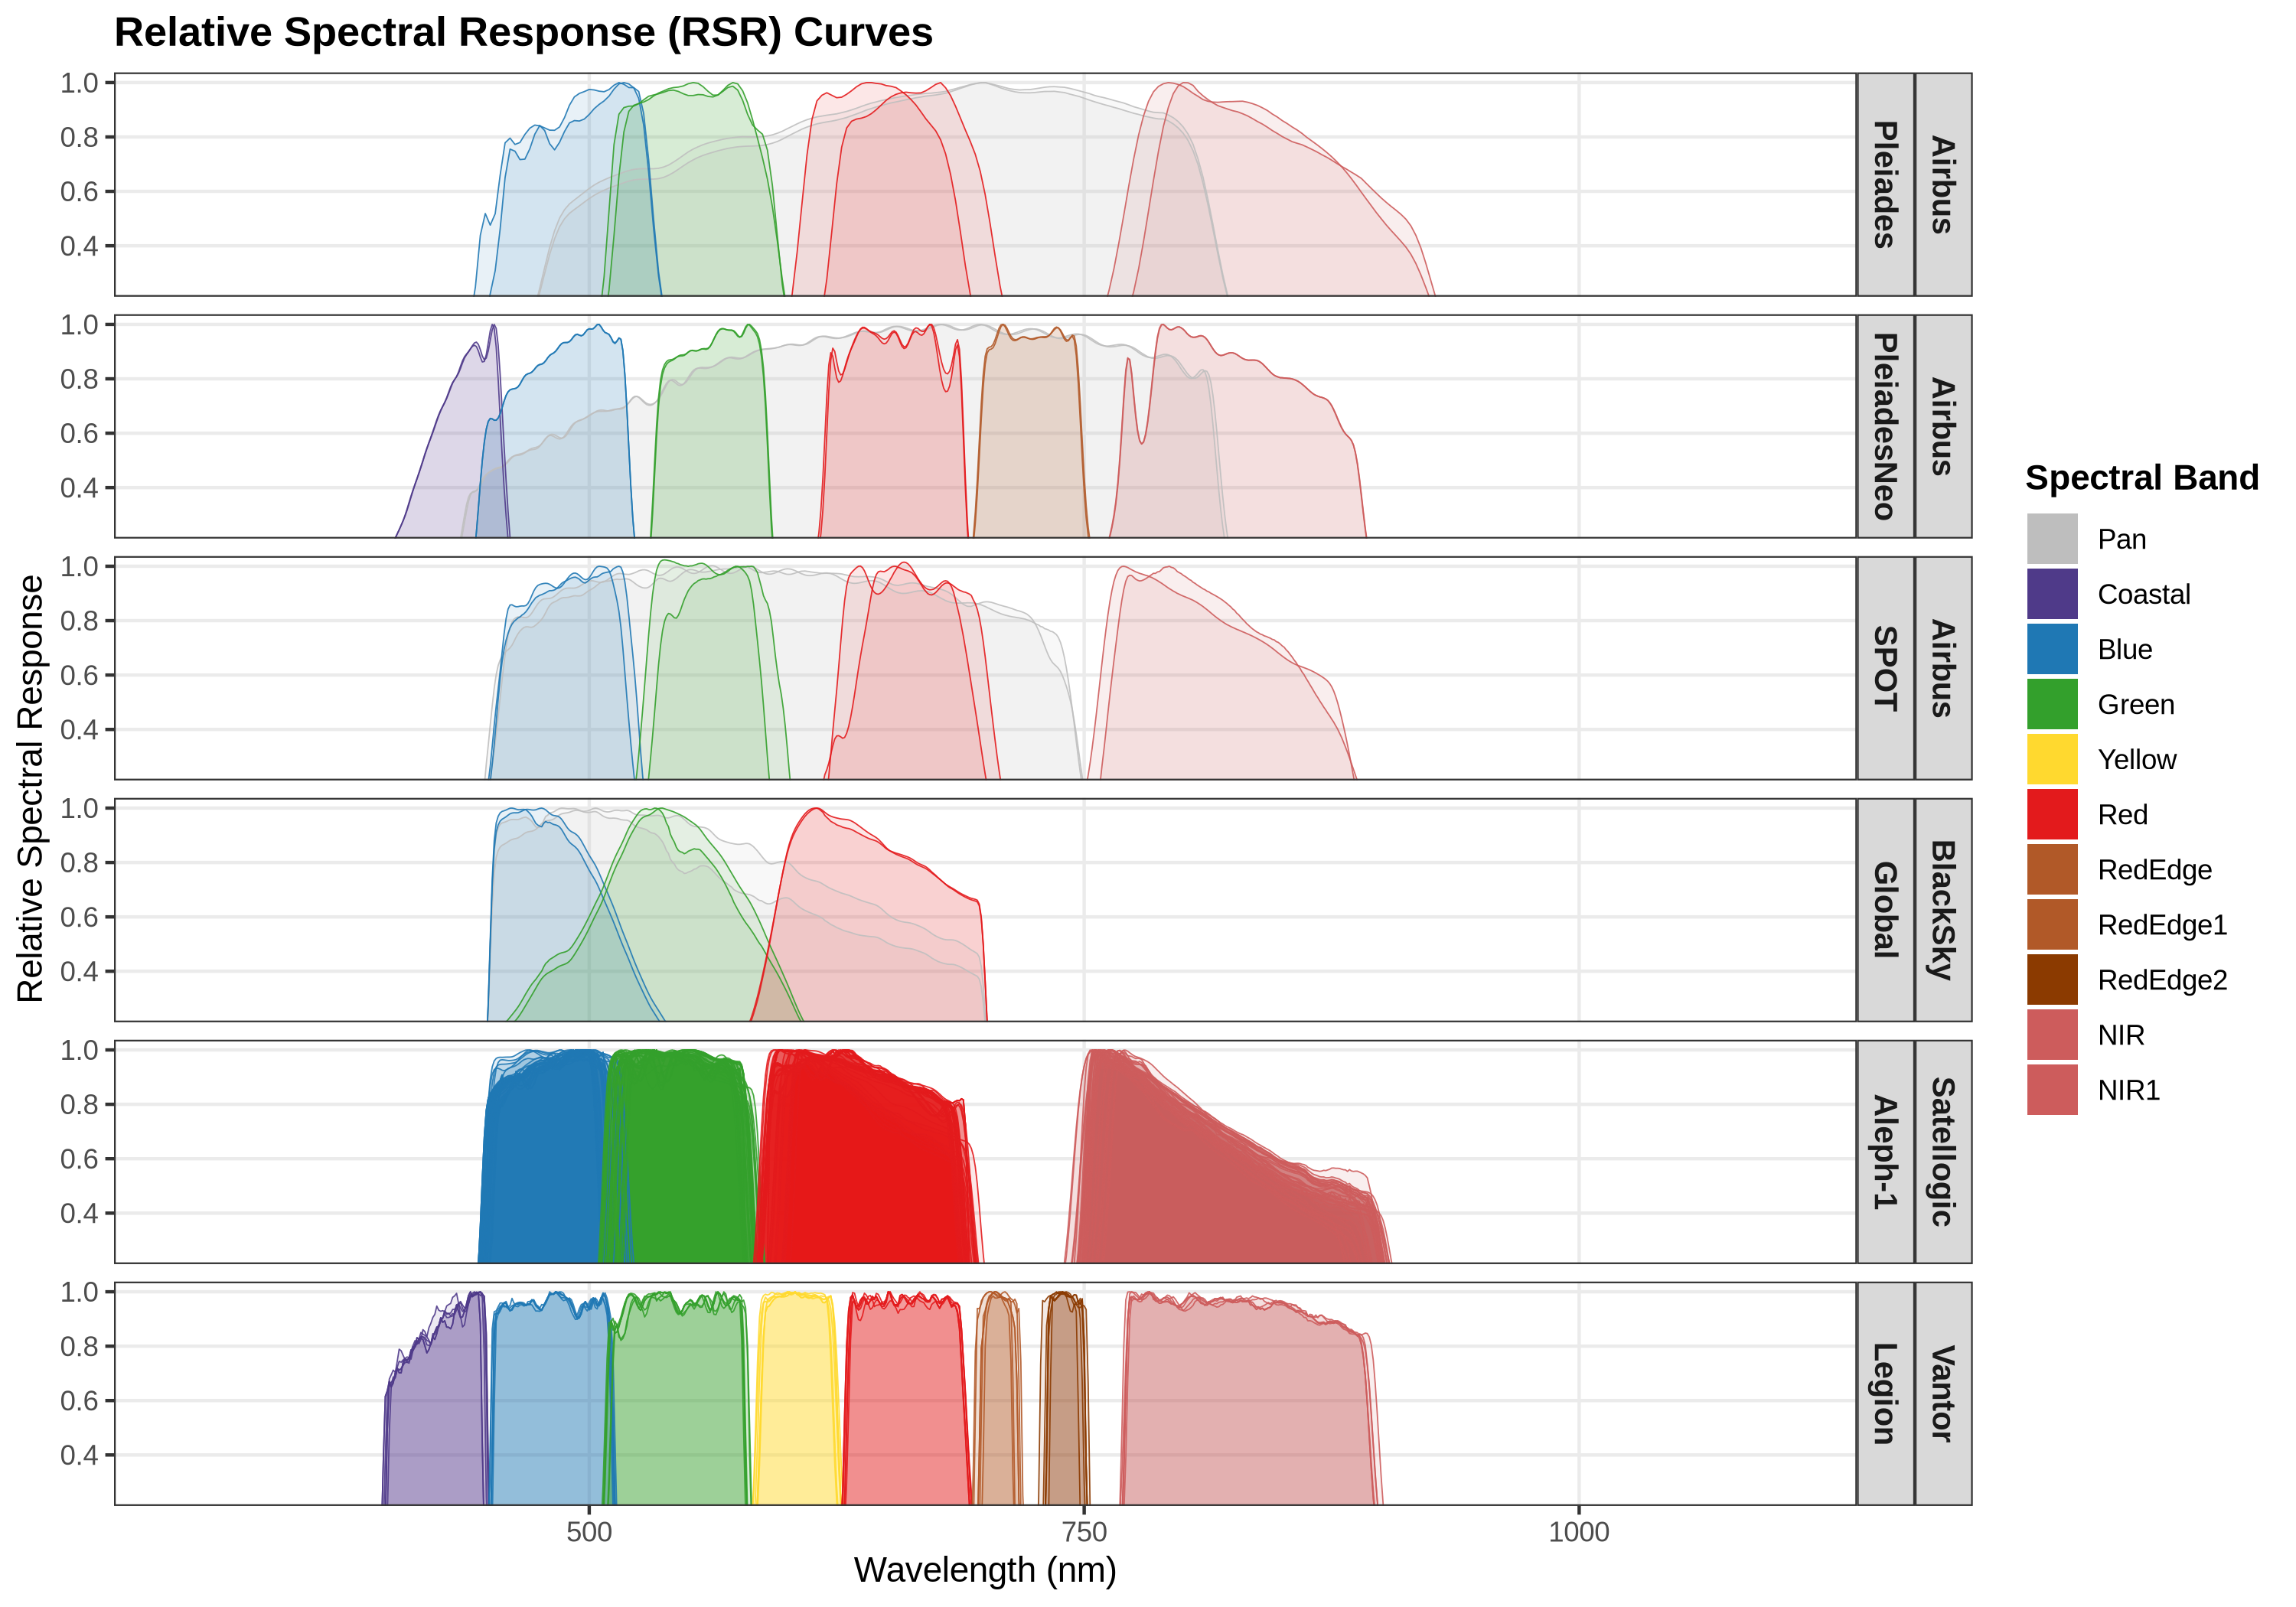

In [10]:
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 300)

# 2. Build the ggplot visualization with filled areas
rsr_plot <- ggplot(df_rsr, aes(x = wavelength_nm, y = rsr, color = band, fill = band, group = interaction(sensor, band))) +
  # NEW: Add filled area layer under the lines
  # position = "identity" prevents the bands from stacking on top of each other
  geom_area(position = "identity", alpha = 0.1, color = NA) + 
  
  # Keep the clear outer boundary lines on top
  geom_line(linewidth = 0.2, alpha = 0.9) +
  coord_cartesian(ylim = c(0.25,1)) +
  
  #facet_wrap(~sensor, ncol = 2, scales = "free_y") +
  
  # Map your explicit hex color vector to BOTH line colors and area fills
  scale_color_manual(values = band_colors, name = "Spectral Band") +
  scale_fill_manual(values = band_colors, name = "Spectral Band") +
  
  labs(
    title = "Relative Spectral Response (RSR) Curves" ,
    #subtitle = "Vantor Legion Satellites (LG01–LG06)",
    x = "Wavelength (nm)",
    y = "Relative Spectral Response"
  ) +
  theme_bw(base_size = 11) +
  theme(
    strip.text = element_text(face = "bold", size = 10),
    panel.grid.minor = element_blank(),
    legend.position = "right",
    legend.title = element_text(face = "bold"),
    plot.title = element_text(face = "bold", size = 13)
  ) +
  facet_grid(affiliation+constellation~.) +
  guides(
        fill = guide_legend(override.aes = list(alpha = 1))
    )

print(rsr_plot)